In [1]:
!pip install yfinance

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Step 1: Download Historical Data

We use Yahoo Finance data to obtain historical stock prices
for Microsoft from 2020–2025.


In [3]:
""" DOWNLOAD DATA """
apple = yf.download(
    "AAPL",
    start="2020-01-01",
    end="2025-01-01",
)
apple.head()

/tmp/ipykernel_793/1516689083.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  apple = yf.download(
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271538,72.331694,71.029915,71.282568,135480400
2020-01-03,71.568909,72.326874,71.345130,71.501534,146322800
2020-01-06,72.139206,72.177707,70.442807,70.693058,118387200
2020-01-07,71.799927,72.403889,71.580958,72.148828,108872000
2020-01-08,72.954918,73.255698,71.503953,71.503953,132079200


In [4]:
apple.columns = apple.columns.get_level_values(0)
apple.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

# Step 2: Explore the Dataset

Before building a strategy, we inspect the dataset
for size, structure, and missing values.

In [5]:
apple.shape #rows and columns

(1258, 5)

In [6]:
apple.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

In [7]:
apple.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1258 non-null   float64
 1   High    1258 non-null   float64
 2   Low     1258 non-null   float64
 3   Open    1258 non-null   float64
 4   Volume  1258 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 59.0 KB


In [8]:
apple["Close"].head()

,Close
Date,
2020-01-02,72.271538
2020-01-03,71.568909
2020-01-06,72.139206
2020-01-07,71.799927
2020-01-08,72.954918


In [9]:
microsoft = yf.download(
    "MSFT",
    start="2020-01-01",
    end="2025-01-01"
)
microsoft.tail()

/tmp/ipykernel_793/3992810956.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  microsoft = yf.download(
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2024-12-24,433.363556,433.629908,428.293377,428.747121,7164500
2024-12-26,432.160126,434.951709,430.700244,433.116954,8194200
2024-12-27,424.683075,429.309384,420.559850,428.697808,18117700
2024-12-30,419.060425,421.743486,416.170224,420.273731,13158700
2024-12-31,415.775696,420.934679,414.947107,420.313230,13246500


In [10]:
microsoft.shape

(1258, 5)

In [11]:
'''microsoft_highest_closing price'''
microsoft['Close'].max()

,0
Ticker,
MSFT,459.460693


In [12]:
microsoft.tail()

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2024-12-24,433.363556,433.629908,428.293377,428.747121,7164500
2024-12-26,432.160126,434.951709,430.700244,433.116954,8194200
2024-12-27,424.683075,429.309384,420.559850,428.697808,18117700
2024-12-30,419.060425,421.743486,416.170224,420.273731,13158700
2024-12-31,415.775696,420.934679,414.947107,420.313230,13246500


# Step 3: Create a 50-Day and 30-Day Moving Average

A moving average smooths out daily price fluctuations and
helps identify trends in the stock price.

In [13]:
apple["MA50"] = apple["Close"].rolling(window=50).mean()
apple["MA30"] = apple["Close"].rolling(window=30).mean()


In [14]:
apple[["Close", "MA30", "MA50"]].tail()

Price,Close,MA30,MA50
Date,,,
2024-12-24,256.339752,238.436332,234.123973
2024-12-26,257.153809,239.587642,234.628849
2024-12-27,253.748535,240.595991,235.106676
2024-12-30,250.382950,241.389565,235.509852
2024-12-31,248.615784,242.230793,235.821158


# Step 4: Visualize Price and Moving Average

We plot the closing price and the 50-day moving average
to observe how the indicator tracks the stock trend.

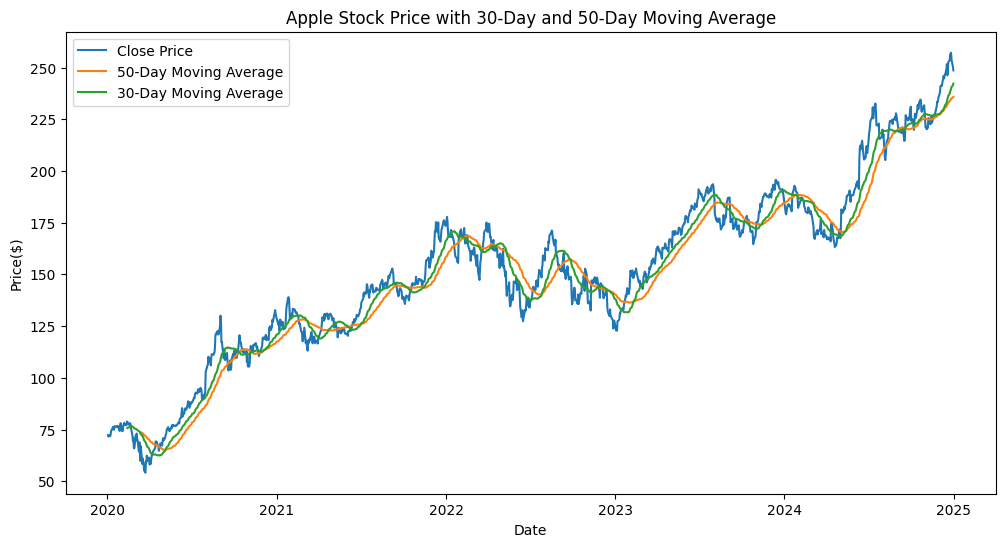

In [15]:
plt.figure(figsize=(12,6))

plt.plot(apple.index,
         apple["Close"],
         label="Close Price")

plt.plot(apple.index,
         apple["MA50"],
         label="50-Day Moving Average")

plt.plot(apple.index,
         apple["MA30"],
         label="30-Day Moving Average")

plt.title("Apple Stock Price with 30-Day and 50-Day Moving Average")


plt.xlabel("Date")
plt.ylabel("Price($)")
plt.legend()
plt.show()

# Research Notes

During Devolpment, a notebook state-issue caused the MA50 column to become entirely NaN. Restarting the runtime and rerunning all the cells resolved the issue, highlighting the importance reproduce.

# Step 5: Generate Trading Signals

We create a trading signal based on the relationship
between the 30-day and 50-day moving averages.

If MA30 > MA50:
    Own the stock

If MA30 < MA50:
    Stay in cash

In [16]:
apple["Position"] = (
    apple["MA30"]>apple["MA50"]
).astype(int)

In [17]:
apple[["Close", "MA30", "MA50", "Position"]].tail()

Price,Close,MA30,MA50,Position
Date,,,,
2024-12-24,256.339752,238.436332,234.123973,1
2024-12-26,257.153809,239.587642,234.628849,1
2024-12-27,253.748535,240.595991,235.106676,1
2024-12-30,250.382950,241.389565,235.509852,1
2024-12-31,248.615784,242.230793,235.821158,1


# Note
Be carefully to avoid look-Ahead bias.

In [18]:
apple["Position"].value_counts()

,count
Position,
1,750
0,508


# Step 6: Calculate Daily Returns

We calculate the percentage change in stock price from
one day to the next. These returns will later be used
to evaluate strategy performance.

In [19]:
apple["Returns"] = apple["Close"].pct_change()

In [20]:
apple[["Close","Returns"]].head(10)

Price,Close,Returns
Date,,
2020-01-02,72.271538,NaN
2020-01-03,71.568909,-0.009722
2020-01-06,72.139206,0.007969
2020-01-07,71.799927,-0.004703
2020-01-08,72.954918,0.016086
2020-01-09,74.504524,0.021241
2020-01-10,74.672958,0.002261
2020-01-13,76.268311,0.021365
2020-01-14,75.238441,-0.013503


# Step 7: Calculate. Strategy Returns
To avoid look-ahead bias, trading positions are shifted by one trading day. This ensures that decisions are only made using information that would have been available at the time.

In [21]:
apple["Strategy_Returns"]= (
    apple["Position"].shift(1)
    * apple["Returns"]
)


In [22]:
apple[["Position", "Returns", "Strategy_Returns"]].head(10)

Price,Position,Returns,Strategy_Returns
Date,,,
2020-01-02,0,NaN,NaN
2020-01-03,0,-0.009722,-0.0
2020-01-06,0,0.007969,0.0
2020-01-07,0,-0.004703,-0.0
2020-01-08,0,0.016086,0.0
2020-01-09,0,0.021241,0.0
2020-01-10,0,0.002261,0.0
2020-01-13,0,0.021365,0.0
2020-01-14,0,-0.013503,-0.0


# Step 8: Simulate Portfolio Growth

We simulate investing an initial portfolio of $10,000 using
the moving-average crossover strategy. The portfolio value
is updated each trading day based on the strategy returns.

In [23]:
initial_capital = 10000

In [24]:
apple["Portfolio"] = (
    initial_capital
    * (1+apple["Strategy_Returns"]).cumprod()
)

In [25]:
apple[["Strategy_Returns", "Portfolio"]].tail()

Price,Strategy_Returns,Portfolio
Date,,
2024-12-24,0.011478,25671.839258
2024-12-26,0.003176,25753.365142
2024-12-27,-0.013242,25412.334805
2024-12-30,-0.013263,25075.279140
2024-12-31,-0.007058,24898.301497


# Step 9: Create a Buy-and-Hold Benchmark

To evaluate the effectiveness of the moving-average strategy,
we compare it against a simple buy-and-hold investment.

In [26]:
apple["BuyHold"] = (
    initial_capital *
    (1 + apple["Returns"]).cumprod()
)

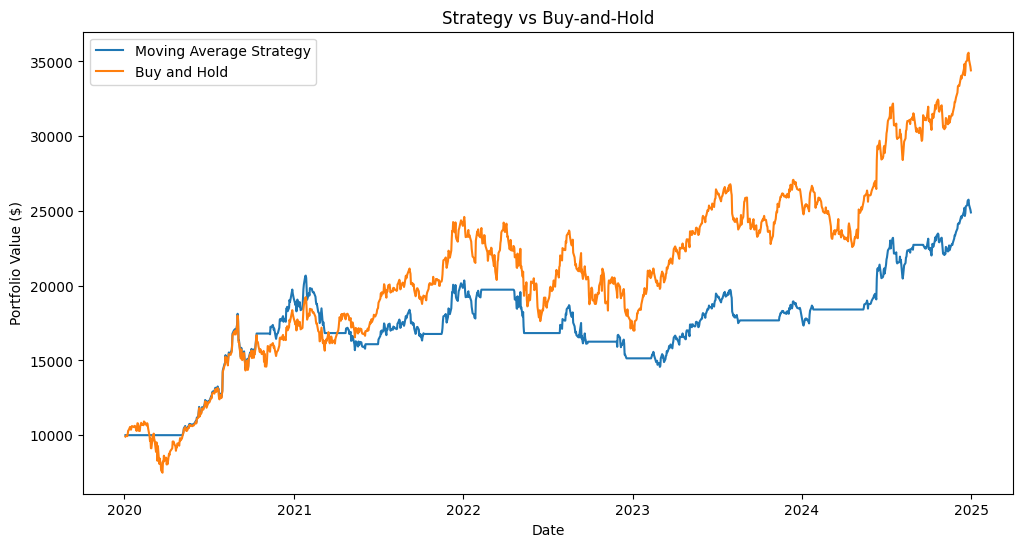

In [27]:
plt.figure(figsize=(12,6))

plt.plot(
    apple.index,
    apple["Portfolio"],
    label="Moving Average Strategy"
)

plt.plot(
    apple.index,
    apple["BuyHold"],
    label="Buy and Hold"
)

plt.title("Strategy vs Buy-and-Hold")

plt.xlabel("Date")

plt.ylabel("Portfolio Value ($)")

plt.legend()

plt.show()

## Analysis of Strategy Performance

After comparing the moving-average crossover strategy with a buy-and-hold benchmark, several observations can be made.

From the beginning of 2020 until early 2021, both portfolios performed similarly, indicating that the strategy was able to capture much of the market's early upward movement. However, after this period, the buy-and-hold portfolio began to outperform the moving-average strategy significantly.

Throughout most of the remaining period, the buy-and-hold portfolio remained above the moving-average strategy. While there was a noticeable decline in the buy-and-hold portfolio between 2022 and 2023, it still maintained a higher overall portfolio value than the strategy. This suggests that although the moving-average strategy reduced exposure during some market fluctuations, it also missed portions of the market's strongest rallies.

By the end of the backtest in early 2025, the buy-and-hold portfolio had grown to approximately $35,000, while the moving-average strategy finished at approximately $25,000.

Another notable observation is that the moving-average portfolio exhibited a much smoother growth path. It experienced fewer sharp increases and decreases, whereas the buy-and-hold portfolio showed much greater volatility. This illustrates one of the primary trade-offs in investing: the moving-average strategy reduced risk by moving into cash during weaker market conditions, but this also caused it to miss periods of rapid market appreciation.

Overall, for the selected time period, the buy-and-hold strategy outperformed the moving-average crossover strategy in terms of total return. However, the moving-average strategy provided a smoother equity curve, demonstrating how different investment strategies balance return and risk.


## SO WHY DID IT UNDERPERFORM ?POSSIBLE HYPOTHESIS:
 1. The moving average react too slowly. By the time teh 30-Day MA crossed the 50-Day MA, much of the upward move has already happened.
 2. Apple experienced a strong bull market. In bull markets, staying invested almost all the time often outperforms startegies that reapeatedly move to cash.
 3. The strategy may perform better during volatile or bearish markets. A moving average crossover is often designed more to protect against large losses than to maximize gains ins a steadily rising market  

## Step 10: Calculate Total Return
The total return measures the overall percentage growth of the portfolio from the initial investment to the end of the backtest.

In [28]:
strategy_total_return = (
    apple["Portfolio"].iloc[-1] - initial_capital
) / initial_capital

buyhold_total_return = (
    apple["BuyHold"].iloc[-1] - initial_capital
) / initial_capital

In [29]:
print(f"Strategy Total Return: {strategy_total_return:.2%}")
print(f"Buy & Hold Total Return: {buyhold_total_return:.2%}")

Strategy Total Return: 148.98%
Buy & Hold Total Return: 244.00%


# Step 11: Calculate Maximum Drawdown
 Maximum drawdown measures the largest decline from a previous portfolio peak. It is coommnoly iused to evaluate the downside risk of an investment

In [30]:
apple["Portfolio_peak"] = apple["Portfolio"].cummax()

In [31]:
apple["Drawdown"] = (
    apple["Portfolio"] - apple["Portfolio_peak"]
) / apple["Portfolio_peak"]

In [32]:
max_drawdown = apple["Drawdown"].min()
print(f"Maximum Drawdown: {max_drawdown:.2%}")

Maximum Drawdown: -29.54%


# Step 12: Calculate Volatility
Volatility measures the vulnerability of daily returns. Higher volatility generally indicates greater investment risk

In [33]:
strategy_volatitlity = apple["Strategy_Returns"].std()
buyhold_volatitlity = apple["Returns"].std()

In [34]:
import numpy as np

strategy_volatility_annual = strategy_volatitlity * np.sqrt(252)

buyhold_volatitlity_annual = buyhold_volatitlity * np.sqrt(252)

In [35]:
print(f"Strategy Annual Volatility: {strategy_volatility_annual:.2%}")
print(f"Buy & Hold Annual Volatility: {buyhold_volatitlity_annual:.2%}")

Strategy Annual Volatility: 21.47%
Buy & Hold Annual Volatility: 31.68%


# Step 13: Calculate the Sharpe Ratio
The Sharpe Ratio measures risk-adjusted performance by comparing the average return of a strategy to the variability of its returns

In [36]:
strategy_mean_return = apple["Strategy_Returns"].mean()
buyhold_mean_return = apple["Returns"].mean()

In [37]:
strategy_sharpe = (
    strategy_mean_return /
    strategy_volatitlity
) * np.sqrt(252)

buyhold_sharpe = (
    buyhold_mean_return /
    buyhold_volatitlity
) * np.sqrt(252)

In [38]:
print(f"Strategy Sharpe Ratio: {strategy_sharpe:.2f}")
print(f"Buy & Hold Sharpe Ratio: {buyhold_sharpe:.2f}")

Strategy Sharpe Ratio: 0.96
Buy & Hold Sharpe Ratio: 0.94


# Step 14: Calculate Buy and Hold Maximum Drawdown

To compare downside risk fairly, we calculate the maximum drawdown of the buy-and-hold portfolio using the same methodology applied to the Moving-average strategy

In [39]:
apple["BuyHold_peak"] = apple["BuyHold"].cummax()

In [40]:
apple["BuyHold_Drawdown"]= (
    apple["BuyHold"] - apple["BuyHold_peak"]
) / apple["BuyHold_peak"]


In [41]:
buyhold_maxdrawdown = apple["BuyHold_Drawdown"].min()

print(f"Buy & Hold Maximum Drawdown: {buyhold_maxdrawdown:.2%}")

Buy & Hold Maximum Drawdown: -31.43%


# Step 15: Create a Performance Summaery Table

In [42]:
results = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown"
    ],
    "Strategy": [
        strategy_total_return,
        strategy_volatility_annual,
        strategy_sharpe,
        max_drawdown
    ],
    "Buy & Hold": [
        buyhold_total_return,
        buyhold_volatitlity_annual,
        buyhold_sharpe,
        buyhold_maxdrawdown
    ]
})
results

,Metric,Strategy,Buy & Hold
0,Total Return,1.489830,2.440023
1,Annual Volatility,0.214655,0.316786
2,Sharpe Ratio,0.959246,0.940356
3,Maximum Drawdown,-0.295374,-0.314273


In [43]:
results_display = results.copy()

results_display.loc[
    results_display["Metric"] != "Sharpe Ratio",
    ["Strategy", "Buy & Hold"]
] = (
    results_display.loc[
        results_display["Metric"] != "Sharpe Ratio",
        ["Strategy", "Buy & Hold"]
    ]
    .map(lambda x: f"{x:.2%}")
)

results_display.loc[
    results_display["Metric"] == "Sharpe Ratio",
    ["Strategy", "Buy & Hold"]
] = (
    results_display.loc[
        results_display["Metric"] == "Sharpe Ratio",
        ["Strategy", "Buy & Hold"]
    ]
    .map(lambda x: f"{x:.2f}")
)

results_display

/tmp/ipykernel_793/2415143273.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['148.98%' '21.47%' '-29.54%']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  results_display.loc[
/tmp/ipykernel_793/2415143273.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['244.00%' '31.68%' '-31.43%']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  results_display.loc[


,Metric,Strategy,Buy & Hold
0,Total Return,148.98%,244.00%
1,Annual Volatility,21.47%,31.68%
2,Sharpe Ratio,0.96,0.94
3,Maximum Drawdown,-29.54%,-31.43%


# Version 2 - Refactoring
To make the project reusable, we begin moving repeated operation into Python functions. This is an effort to make the code reusable and maintainable.   

In [44]:
def add_moving_averages(df):
  """
  Add 30-day and 50-day moving averages to a stock price Dataframe.

  Parameters
  ------------
  df: pandas.DataFrame
      Stock price data.

  Returns
  ------------
  pandas.Dataframe
      Dataframe with MA30 and MA50 columns.

  """

  df["MA30"] = df["Close"].rolling(window=30).mean()
  df["MA50"] = df["Close"].rolling(window=50).mean()

  return df

In [45]:
apple = add_moving_averages(apple)

In [46]:
apple[["Close", "MA30", "MA50"]].tail()

Price,Close,MA30,MA50
Date,,,
2024-12-24,256.339752,238.436332,234.123973
2024-12-26,257.153809,239.587642,234.628849
2024-12-27,253.748535,240.595991,235.106676
2024-12-30,250.382950,241.389565,235.509852
2024-12-31,248.615784,242.230793,235.821158


In [47]:
print(apple["Close"].head())

Date
2020-01-02    72.271538
2020-01-03    71.568909
2020-01-06    72.139206
2020-01-07    71.799927
2020-01-08    72.954918
Name: Close, dtype: float64


In [48]:
print(type(apple["Close"]))

<class 'pandas.core.series.Series'>


In [49]:
apple = add_moving_averages(apple)

print(apple[["MA30", "MA50"]].head(35))

Price            MA30  MA50
Date                       
2020-01-02        NaN   NaN
2020-01-03        NaN   NaN
2020-01-06        NaN   NaN
2020-01-07        NaN   NaN
2020-01-08        NaN   NaN
2020-01-09        NaN   NaN
2020-01-10        NaN   NaN
2020-01-13        NaN   NaN
2020-01-14        NaN   NaN
2020-01-15        NaN   NaN
2020-01-16        NaN   NaN
2020-01-17        NaN   NaN
2020-01-21        NaN   NaN
2020-01-22        NaN   NaN
2020-01-23        NaN   NaN
2020-01-24        NaN   NaN
2020-01-27        NaN   NaN
2020-01-28        NaN   NaN
2020-01-29        NaN   NaN
2020-01-30        NaN   NaN
2020-01-31        NaN   NaN
2020-02-03        NaN   NaN
2020-02-04        NaN   NaN
2020-02-05        NaN   NaN
2020-02-06        NaN   NaN
2020-02-07        NaN   NaN
2020-02-10        NaN   NaN
2020-02-11        NaN   NaN
2020-02-12        NaN   NaN
2020-02-13  75.728502   NaN
2020-02-14  75.932000   NaN
2020-02-18  76.111081   NaN
2020-02-19  76.308297   NaN
2020-02-20  76.49013

In [50]:
print(apple.columns)

Index(['Close', 'High', 'Low', 'Open', 'Volume', 'MA50', 'MA30', 'Position',
       'Returns', 'Strategy_Returns', 'Portfolio', 'BuyHold', 'Portfolio_peak',
       'Drawdown', 'BuyHold_peak', 'BuyHold_Drawdown'],
      dtype='object', name='Price')


In [51]:
# debugging
print(type(apple))
print(type(apple["Close"]))
print(apple.columns)

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>
Index(['Close', 'High', 'Low', 'Open', 'Volume', 'MA50', 'MA30', 'Position',
       'Returns', 'Strategy_Returns', 'Portfolio', 'BuyHold', 'Portfolio_peak',
       'Drawdown', 'BuyHold_peak', 'BuyHold_Drawdown'],
      dtype='object', name='Price')
